In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../')

import oasis_dla

In [2]:
circuit = qiskit.QuantumCircuit(1)
circuit.h(0)
circuit.ry(0, 0)

gen = oasis_dla.extract_generators(circuit)

display(gen)

# dla = oasis_dla.construct_dla(gen)

# print(f"Computed DLA: \n{dla}")
# print(f"dim(g): {len(dla)}")

[array([[-1.+0.j,  1.+0.j],
        [ 1.+0.j,  1.+0.j]]),
 array([[0.+0.j, 0.-1.j],
        [0.+1.j, 0.+0.j]])]

In [3]:
# print(f"Var(cost) ~ 1/dim(g) = {1/len(dla)}")

In [4]:
vqls = oasis_dla.VQLS(qubits=1)

A = np.array([
    [1, 1],
    [0, 5]
])

b = np.array([
    [1],
    [-1]
])

X = np.array([
    [0, 1],
    [1, 0]
])

Y = np.array([
    [0, -1j],
    [1j, 0]
])

Z = np.array([
    [1, 0],
    [0, -1]
])

# pauli_matrices = [np.eye(2), X, Y, Z]
# coeffs = [0.5 * np.trace(P @ A) for P in pauli_matrices]

# sum = np.zeros((2, 2), np.complex128)
# for i, p in enumerate(pauli_matrices):
#     sum += (coeffs[i] * p)
# sum

solution = vqls.solve(A, b, shots=10_000)

print(solution.solution())
solution.get_probabilities()
print(np.linalg.solve(A, b))


 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.7200464103316335e-15
       x: [ 4.382e+00]
     nit: 36
   maxcv: 0.0
    nfev: 26
[[ 1.19999999+0.j]
 [-0.2       +0.j]]
[[ 1.2]
 [-0.2]]


 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 3.885780586188048e-15
       x: [ 4.382e+00]
     nit: 42
   maxcv: 0.0
    nfev: 25
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 4.163336342344337e-15
       x: [ 4.382e+00]
     nit: 42
   maxcv: 0.0
    nfev: 23
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 3.608224830031759e-15
       x: [ 4.382e+00]
     nit: 46
   maxcv: 0.0
    nfev: 24
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.942091015256665e-15
       x: [ 4.382e+00]
     nit: 43
   maxcv: 0.0
    nfev: 26
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.4424906541753444e-15
       x: [ 4.382e+00]
     nit: 42
   maxcv: 0.0
    nfev: 25
 message: The lower bound for the 

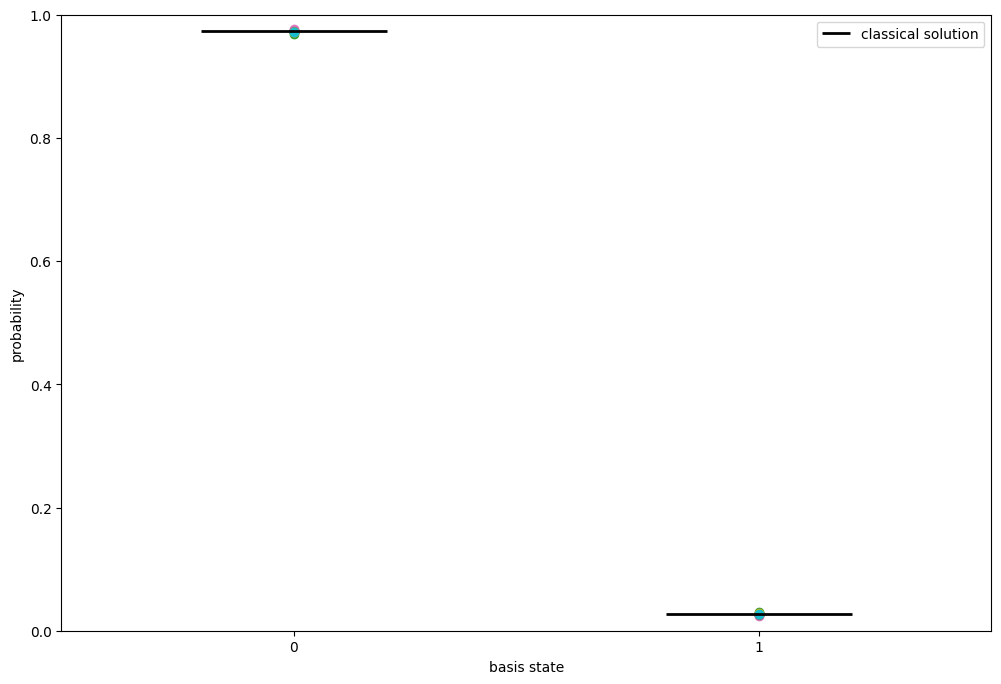

In [5]:
prob_list = []
for i in range(0, 20):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 3.2751579226442118e-15
       x: [ 4.382e+00]
     nit: 42
   maxcv: 0.0
    nfev: 23
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.8318679906315083e-15
       x: [ 4.382e+00]
     nit: 38
   maxcv: 0.0
    nfev: 22
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 3.0531133177191805e-15
       x: [ 4.382e+00]
     nit: 44
   maxcv: 0.0
    nfev: 24
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 3.941291737419306e-15
       x: [ 4.382e+00]
     nit: 41
   maxcv: 0.0
    nfev: 22
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 3.608224830031759e-15
       x: [ 4.382e+00]
     nit: 40
   maxcv: 0.0
    nfev: 24
 message: The lower bound for th

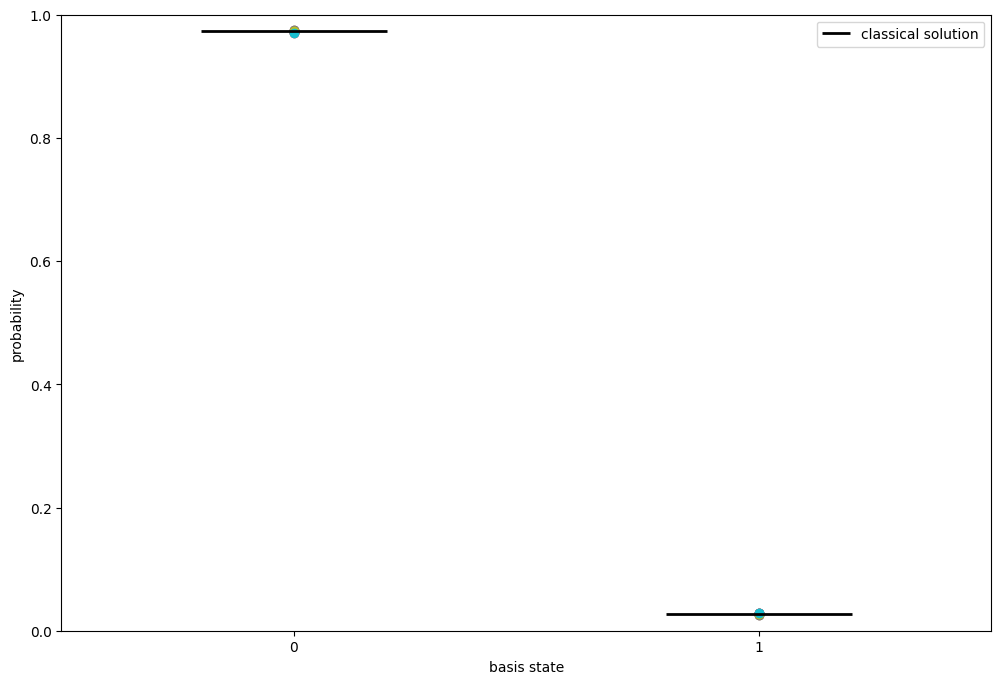

In [6]:
prob_list = []
for i in range(0, 20):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))

ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

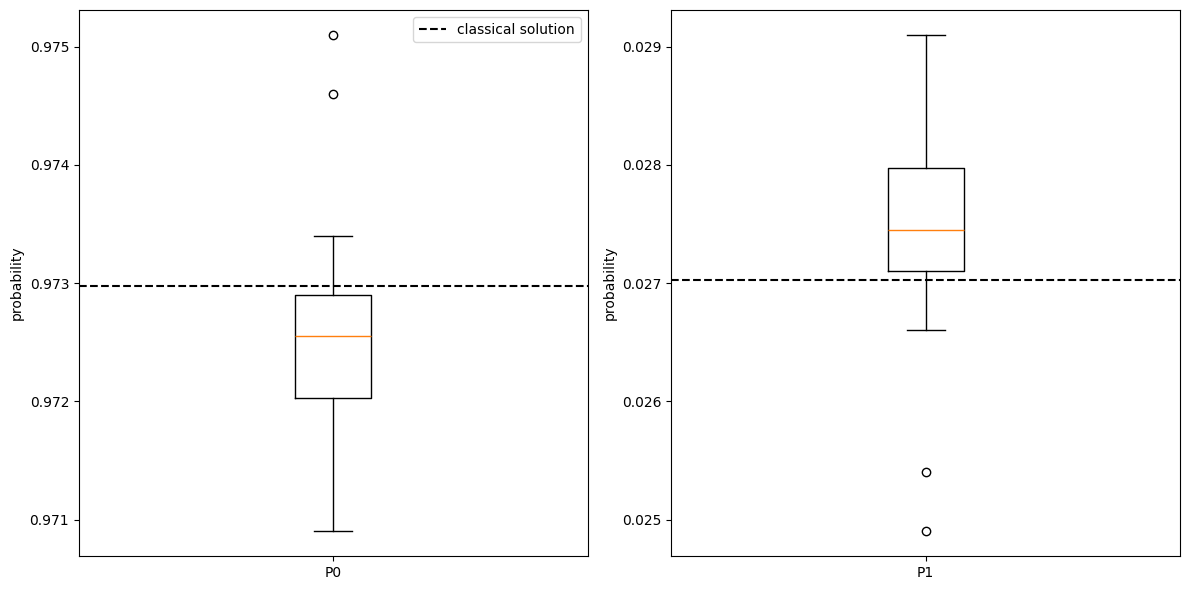

In [7]:
P0s = [probs.get("0", 0) for probs in prob_list]
P1s = [probs.get("1", 0) for probs in prob_list]

# separate panel
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, data, p_true, label in zip(axes, [P0s, P1s], p_classical, ["P0", "P1"]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
plt.tight_layout()
plt.show()

# testing 1 qubit vqls on a suite of real and then complex matrices

In [8]:
random_c = lambda: random.random() + 1j * random.random()
random_r = random.random

A = np.array([
    [1, random_c()],
    [1, 1]
])
b = 1/np.sqrt(2) * np.array([
    [1],
    [1]
])
print(A)
qres = vqls.solve(A, b).solution()#.reshape(-1, 1)
cres = np.linalg.solve(A,b)
print(f"Quantum Solution: \n{qres}\n")
print(f"Classical Solution: \n{cres}\n")

# project qres onto cres
np.linalg.norm(qres - cres)

[[1.        +0.j         0.41631853+0.02195338j]
 [1.        +0.j         1.        +0.j        ]]
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.7763568394002505e-15
       x: [-1.571e+00]
     nit: 38
   maxcv: 0.0
    nfev: 22
Quantum Solution: 
[[7.07106708e-01-1.12699044e-09j]
 [1.02671241e-07-1.63637971e-16j]]

Classical Solution: 
[[0.70710678+0.j]
 [0.        +0.j]]



np.float64(1.2581354281057585e-07)

In [9]:
def res_diff(x, y):
    return 1 - np.linalg.norm(x-y)

def test_vqls(b=None, shots=1):
    Ai = [ # random data set of matrices
        np.array([
            [1, random_c()],
            [random_c(), random_c()]
        ]) for _ in range(shots)
    ]

    if b is None:
        b = 1/np.sqrt(2) * np.array([
            [1],
            [1]
        ])

    accuracies = []
    for A in Ai:
        # print(b)
        q_soln = vqls.solve(A, b).solution()
        c_soln = np.linalg.solve(A, b)
        # print(f"Quantum Solution: \n{q_soln}\n")
        # print(f"Classical Solution: \n{c_soln}\n")

        diff = res_diff(q_soln, c_soln)
        # print(f"Accuracy: {diff}")
        accuracies.append(diff)

    # print(accuracies)

    return accuracies

accuracies = test_vqls()
avg_diff = sum(accuracies) / len(accuracies)

print(f"Average Quantum Solution Accuracy: {avg_diff*100:.2f}%")

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.19512110931648224
       x: [ 4.241e-01]
     nit: 31
   maxcv: 0.0
    nfev: 16
Average Quantum Solution Accuracy: 47.55%


In [10]:
avg_diff, accuracies

(np.float64(0.4755409047623145), [np.float64(0.4755409047623145)])

In [11]:
# plt.plot(np.linspace(0, len(accuracies), 1), accuracies)
# plt.axhline(avg_diff, color='black', linestyle='--', label="Average")
# plt.ylabel("Accuracy")
# plt.xlabel("Test # (random matrix)")
# plt.title("Constant Top Right Entry")
# plt.legend()

[array([[0.08485849+0.1053754j , 0.94959289+0.64958951j],
       [0.52457936+0.78402363j, 0.7409471 +0.1476809j ]]), array([[0.58934403+0.64945989j, 0.44996639+0.78088923j],
       [0.95118908+0.19285454j, 0.67846256+0.85295727j]]), array([[0.02708772+0.16151505j, 0.2341104 +0.98254081j],
       [0.89152451+0.6540114j , 0.45756517+0.31316973j]])]
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0015126044053074272
       x: [ 3.943e-01]
     nit: 36
   maxcv: 0.0
    nfev: 16
0.9402806151697349
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.014333523201708942
       x: [ 1.601e+00]
     nit: 39
   maxcv: 0.0
    nfev: 19
0.49195438974218275
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.12592234988778106
       x: [ 6.559e-01]
     nit: 37
   maxcv: 0.0
    nfev: 17
0.5056174994356956
 message: The low

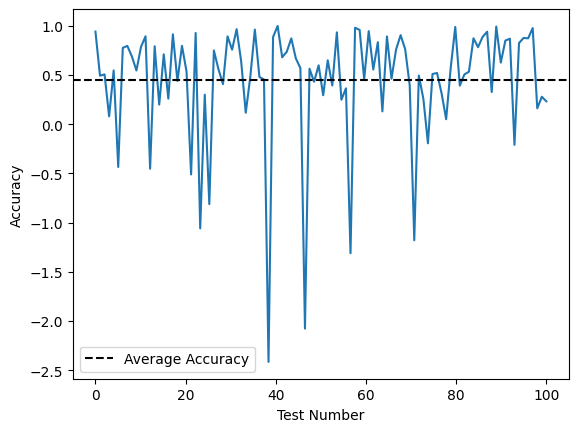

In [12]:
vqls_ry = oasis_dla.VQLS(qubits=1, ansatz_type=0)
vqls_rz = oasis_dla.VQLS(qubits=1, ansatz_type=1)

data = vqls.generate_dataset(random_entries=[1+1j, 2+1j, 3+1j, 4+1j], shots=100)
print(data[:3])

# 1 param ansatz ry h
accuracies = vqls_ry.accuracy_test(data)
vqls_ry.plot_tests(accuracies)

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 9.992007221626409e-15
       x: [ 3.872e-01 -1.810e-01]
     nit: 41
   maxcv: 0.0
    nfev: 29
0.9999998468007038
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 9.159339953157541e-15
       x: [ 7.905e-01  1.935e+00]
     nit: 45
   maxcv: 0.0
    nfev: 42
0.9999996085364247
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 4.9404924595819466e-15
       x: [ 3.369e-01 -1.375e+00]
     nit: 40
   maxcv: 0.0
    nfev: 37
0.9999999099029588
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 6.661338147750939e-16
       x: [-1.296e-02  1.709e+00]
     nit: 48
   maxcv: 0.0
    nfev: 38
0.9999999966907978
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun:

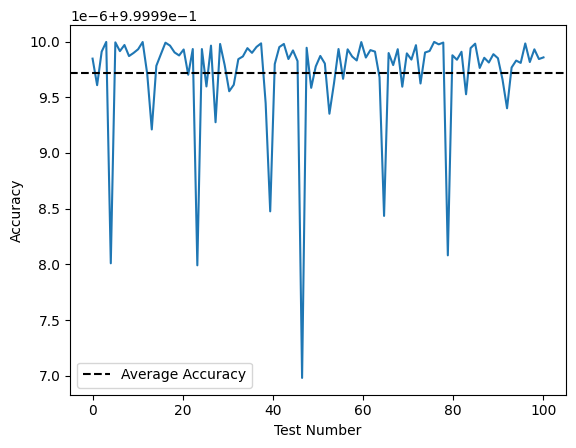

In [13]:
# 2 param ansatz rz ry h
accuracies = vqls_rz.accuracy_test(data)
vqls_rz.plot_tests(accuracies)

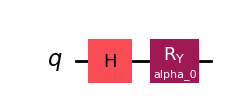

In [14]:
vqls_ry.ansatz.draw('mpl')

In [15]:
generators = oasis_dla.extract_generators(vqls_ry.ansatz)
print(generators)
dla_ry = oasis_dla.construct_dla(generators)
dla_ry

# linear_indep(generators)

[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]])]
[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]])]


AttributeError: 'list' object has no attribute 'flatten'

In [ ]:
generators = oasis_dla.extract_generators(vqls_rz.ansatz)
generators
# dla_rz = oasis_dla.construct_dla(generators)
# dla_rz

[array([[-1.+0.j,  1.+0.j],
        [ 1.+0.j,  1.+0.j]]),
 array([[0.+0.j, 0.-1.j],
        [0.+1.j, 0.+0.j]]),
 array([[ 1.+0.j,  0.+0.j],
        [ 0.+0.j, -1.+0.j]])]